In [1]:
# Import the required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

In [2]:
# Load the Fashion-MNIST training and testing datasets
train_data = pd.read_csv("fashion-mnist_train.csv")
test_data = pd.read_csv("fashion-mnist_test.csv")

# Display the dataset dimensions
print("Training dataset shape:", train_data.shape)
print("Testing dataset shape:", test_data.shape)

# Display the first five rows
print(train_data.head())

Training dataset shape: (60000, 785)
Testing dataset shape: (10000, 785)
   label  pixel1  pixel2  pixel3  pixel4  pixel5  pixel6  pixel7  pixel8  \
0      2       0       0       0       0       0       0       0       0   
1      9       0       0       0       0       0       0       0       0   
2      6       0       0       0       0       0       0       0       5   
3      0       0       0       0       1       2       0       0       0   
4      3       0       0       0       0       0       0       0       0   

   pixel9  ...  pixel775  pixel776  pixel777  pixel778  pixel779  pixel780  \
0       0  ...         0         0         0         0         0         0   
1       0  ...         0         0         0         0         0         0   
2       0  ...         0         0         0        30        43         0   
3       0  ...         3         0         0         0         0         1   
4       0  ...         0         0         0         0         0         0   

 

In [3]:
# Separate the target labels from the pixel features
X_train = train_data.drop("label", axis=1)
y_train = train_data["label"]

X_test = test_data.drop("label", axis=1)
y_test = test_data["label"]

# Display the dimensions of features and labels
print("Training features:", X_train.shape)
print("Training labels:", y_train.shape)
print("Testing features:", X_test.shape)
print("Testing labels:", y_test.shape)

Training features: (60000, 784)
Training labels: (60000,)
Testing features: (10000, 784)
Testing labels: (10000,)


In [4]:
# Display the number of images belonging to each class
print("Training class distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting class distribution:")
print(y_test.value_counts().sort_index())

Training class distribution:
label
0    6000
1    6000
2    6000
3    6000
4    6000
5    6000
6    6000
7    6000
8    6000
9    6000
Name: count, dtype: int64

Testing class distribution:
label
0    1000
1    1000
2    1000
3    1000
4    1000
5    1000
6    1000
7    1000
8    1000
9    1000
Name: count, dtype: int64


In [5]:
# Initialize the StandardScaler
scaler = StandardScaler()

# Fit the scaler on training data and transform it
X_train_scaled = scaler.fit_transform(X_train)

# Transform the testing data using the same scaler
X_test_scaled = scaler.transform(X_test)

# Display the scaled data dimensions
print("Scaled training data shape:", X_train_scaled.shape)
print("Scaled testing data shape:", X_test_scaled.shape)

Scaled training data shape: (60000, 784)
Scaled testing data shape: (10000, 784)


In [13]:
import numpy as np

# Define the custom PCA class
class PCA:
    def __init__(self, n_components=None):
        self.n_components = n_components
        self.components_ = None
        self.explained_variance_ = None
        self.explained_variance_ratio_ = None
        self.mean_ = None

    def fit(self, X):
        # Convert input data to a NumPy array
        X = np.asarray(X, dtype=np.float64)
        n_samples, n_features = X.shape

        # Validate the number of components
        if (self.n_components is not None and
                self.n_components > min(n_samples, n_features)):
            raise ValueError("n_components exceeds the allowed limit.")

        # Calculate the mean of each feature
        self.mean_ = np.mean(X, axis=0)

        # Center the data
        X_centered = X - self.mean_

        # Calculate the covariance matrix
        cov_matrix = np.cov(X_centered, rowvar=False)

        # Calculate eigenvalues and eigenvectors
        eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)

        # Sort eigenvalues in descending order
        sorted_indices = np.argsort(eigenvalues)[::-1]
        eigenvalues = eigenvalues[sorted_indices]
        eigenvectors = eigenvectors[:, sorted_indices]

        # Calculate explained variance ratios
        total_variance = np.sum(eigenvalues)
        if total_variance > 0:
            variance_ratio = eigenvalues / total_variance
        else:
            variance_ratio = eigenvalues

        # Select the principal components
        k = (self.n_components if self.n_components is not None
             else n_features)

        self.components_ = eigenvectors[:, :k].T
        self.explained_variance_ = eigenvalues[:k]
        self.explained_variance_ratio_ = variance_ratio[:k]

        # Display results
        print("Covariance matrix shape:", cov_matrix.shape)
        print("Number of eigenvalues:", len(eigenvalues))
        print("Eigenvectors shape:", eigenvectors.shape)
        print("Selected components:", k)

        return self

    def transform(self, X):
        X = np.asarray(X, dtype=np.float64)
        X_centered = X - self.mean_
        return np.dot(X_centered, self.components_.T)

    def fit_transform(self, X):
        return self.fit(X).transform(X)

    def inverse_transform(self, X_projected):
        return np.dot(X_projected, self.components_) + self.mean_

In [14]:
# Test PCA using a small sample of the scaled training data
pca_test = PCA(n_components=2)
X_test_pca = pca_test.fit_transform(X_train_scaled[:1000])

print("Original sample shape:", X_train_scaled[:1000].shape)
print("Reduced sample shape:", X_test_pca.shape)
print("Explained variance ratio:", pca_test.explained_variance_ratio_)

Covariance matrix shape: (784, 784)
Number of eigenvalues: 784
Eigenvectors shape: (784, 784)
Selected components: 2
Original sample shape: (1000, 784)
Reduced sample shape: (1000, 2)
Explained variance ratio: [0.21638496 0.14019595]


In [15]:
# Initialize PCA with two principal components
pca = PCA(n_components=2)

# Fit PCA on the scaled training data and transform it
X_train_pca = pca.fit_transform(X_train_scaled)

# Display the reduced data dimensions
print("Original training data shape:", X_train_scaled.shape)
print("Reduced training data shape:", X_train_pca.shape)

# Display explained variance ratios
print("Explained variance ratio:", pca.explained_variance_ratio_)
print(
    "Total variance retained:",
    np.sum(pca.explained_variance_ratio_) * 100,
    "%"
)

Covariance matrix shape: (784, 784)
Number of eigenvalues: 784
Eigenvectors shape: (784, 784)
Selected components: 2
Original training data shape: (60000, 784)
Reduced training data shape: (60000, 2)
Explained variance ratio: [0.22057176 0.14395563]
Total variance retained: 36.45273855029696 %


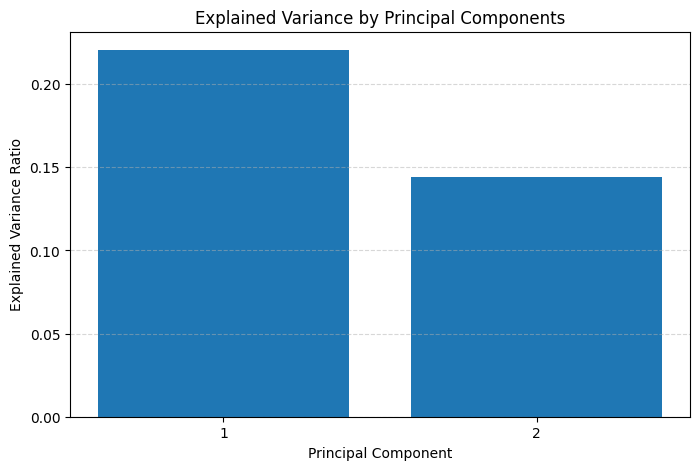

In [16]:
# Plot the explained variance of the selected components
plt.figure(figsize=(8, 5))

components = np.arange(1, len(pca.explained_variance_ratio_) + 1)

plt.bar(components, pca.explained_variance_ratio_)

plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.title("Explained Variance by Principal Components")
plt.xticks(components)
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.show()

Covariance matrix shape: (784, 784)
Number of eigenvalues: 784
Eigenvectors shape: (784, 784)
Selected components: 784


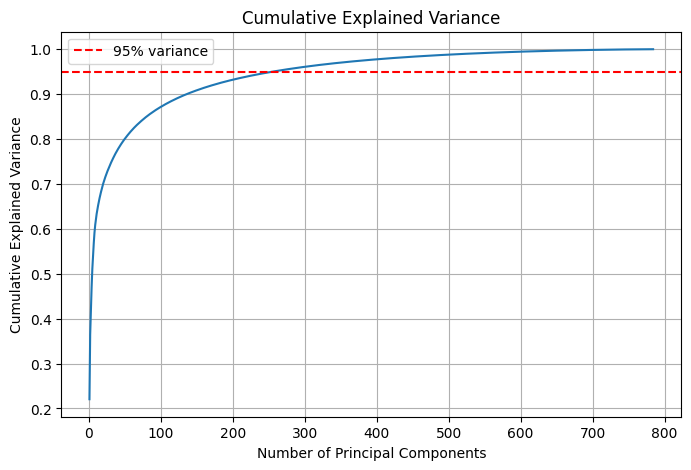

Components needed for 95% variance: 256


In [17]:
# Fit PCA with all available components
pca_all = PCA()
pca_all.fit(X_train_scaled)

# Calculate cumulative explained variance
cumulative_variance = np.cumsum(
    pca_all.explained_variance_ratio_
)

# Plot cumulative explained variance
plt.figure(figsize=(8, 5))
plt.plot(
    np.arange(1, len(cumulative_variance) + 1),
    cumulative_variance
)

plt.axhline(y=0.95, color="red", linestyle="--",
            label="95% variance")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("Cumulative Explained Variance")
plt.legend()
plt.grid(True)
plt.show()

# Find the number of components needed for 95% variance
n_components_95 = np.argmax(
    cumulative_variance >= 0.95
) + 1

print("Components needed for 95% variance:",
      n_components_95)

In [18]:
# Initialize PCA with the number of components needed for 95% variance
pca_95 = PCA(n_components=n_components_95)

# Fit PCA on training data and transform it
X_train_pca_95 = pca_95.fit_transform(X_train_scaled)

# Transform testing data using the fitted PCA
X_test_pca_95 = pca_95.transform(X_test_scaled)

# Display the dimensions
print("Original training shape:", X_train_scaled.shape)
print("Reduced training shape:", X_train_pca_95.shape)
print("Original testing shape:", X_test_scaled.shape)
print("Reduced testing shape:", X_test_pca_95.shape)

print(
    "Variance retained (%):",
    np.sum(pca_95.explained_variance_ratio_) * 100
)

Covariance matrix shape: (784, 784)
Number of eigenvalues: 784
Eigenvectors shape: (784, 784)
Selected components: 256
Original training shape: (60000, 784)
Reduced training shape: (60000, 256)
Original testing shape: (10000, 784)
Reduced testing shape: (10000, 256)
Variance retained (%): 95.02224534091704


Covariance matrix shape: (784, 784)
Number of eigenvalues: 784
Eigenvectors shape: (784, 784)
Selected components: 2


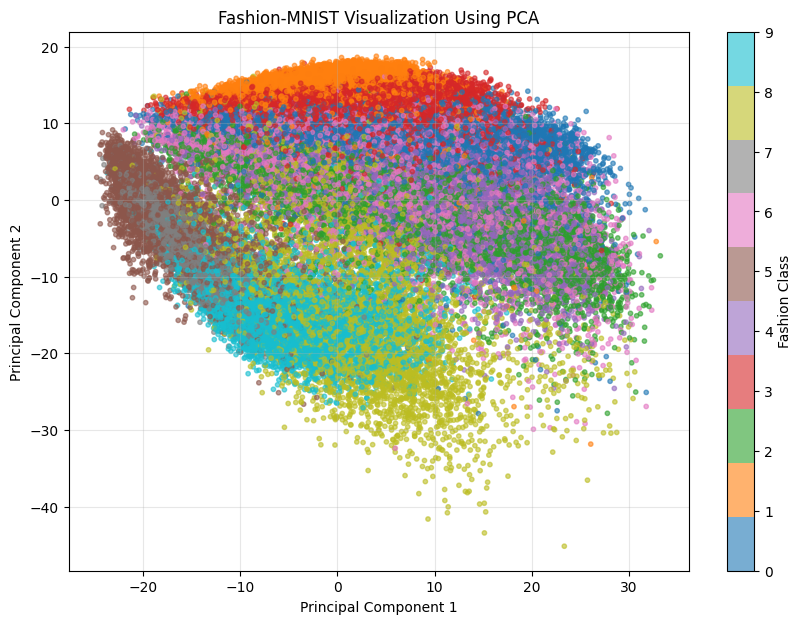

In [19]:
# Fit PCA with two components for visualization
pca_2d = PCA(n_components=2)
X_train_pca_2d = pca_2d.fit_transform(X_train_scaled)

# Plot the reduced data using the original class labels
plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    X_train_pca_2d[:, 0],
    X_train_pca_2d[:, 1],
    c=y_train,
    cmap="tab10",
    s=10,
    alpha=0.6
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Fashion-MNIST Visualization Using PCA")
plt.colorbar(scatter, label="Fashion Class")
plt.grid(True, alpha=0.3)
plt.show()

In [20]:
# Transform the scaled training data into two components
X_projected = pca_2d.transform(X_train_scaled)

# Reconstruct the original feature space
X_reconstructed = pca_2d.inverse_transform(X_projected)

# Calculate the reconstruction mean squared error
reconstruction_error = np.mean(
    (X_train_scaled - X_reconstructed) ** 2
)

print("Original data shape:", X_train_scaled.shape)
print("Reconstructed data shape:", X_reconstructed.shape)
print("Reconstruction MSE:", reconstruction_error)

Original data shape: (60000, 784)
Reconstructed data shape: (60000, 784)
Reconstruction MSE: 0.6354726144970285


In [22]:
# Train Logistic Regression on a representative subset
model_original = LogisticRegression(
    max_iter=200,
    solver="lbfgs"
)

# Use 10,000 training images to reduce execution time
model_original.fit(
    X_train_scaled[:10000],
    y_train[:10000]
)

# Predict using the test dataset
y_pred_original = model_original.predict(X_test_scaled)

# Calculate accuracy
accuracy_original = accuracy_score(y_test, y_pred_original)

print("Accuracy using original features:",
      accuracy_original * 100, "%")

Accuracy using original features: 80.83 %


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [23]:
# Initialize Logistic Regression for PCA-reduced data
model_pca = LogisticRegression(
    max_iter=200,
    solver="lbfgs"
)

# Train using the PCA-reduced training data
model_pca.fit(
    X_train_pca_95[:10000],
    y_train[:10000]
)

# Predict labels using the reduced test data
y_pred_pca = model_pca.predict(X_test_pca_95)

# Calculate classification accuracy
accuracy_pca = accuracy_score(y_test, y_pred_pca)

print("Accuracy using PCA-reduced features:",
      accuracy_pca * 100, "%")

Accuracy using PCA-reduced features: 82.31 %


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


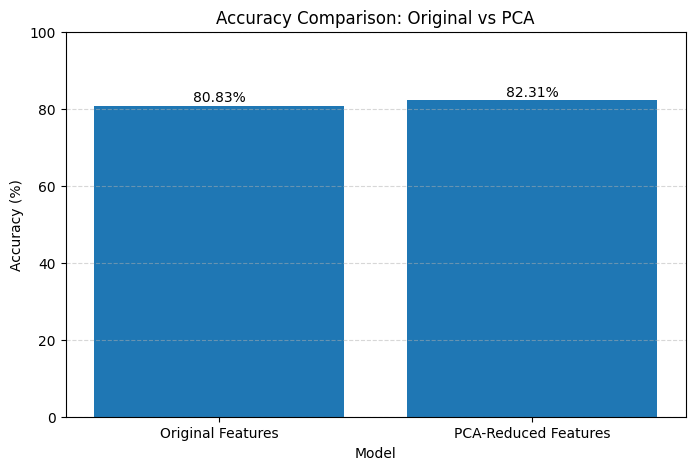

In [24]:
# Compare model accuracies visually
models = ["Original Features", "PCA-Reduced Features"]
accuracies = [
    accuracy_original * 100,
    accuracy_pca * 100
]

plt.figure(figsize=(8, 5))
bars = plt.bar(models, accuracies)

plt.ylabel("Accuracy (%)")
plt.xlabel("Model")
plt.title("Accuracy Comparison: Original vs PCA")
plt.ylim(0, 100)

# Display accuracy values above the bars
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 1,
        f"{height:.2f}%",
        ha="center"
    )

plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()

In [25]:
# Display the final results of the PCA experiment
print("----- PCA EXPERIMENT RESULTS -----")

print("Original number of features:", X_train_scaled.shape[1])
print("Number of selected components:", n_components_95)

print(
    "Total variance retained:",
    round(np.sum(pca_95.explained_variance_ratio_) * 100, 2),
    "%"
)

print(
    "Reconstruction error using 2 components:",
    round(reconstruction_error, 4)
)

print(
    "Accuracy using original features:",
    round(accuracy_original * 100, 2), "%"
)

print(
    "Accuracy using PCA-reduced features:",
    round(accuracy_pca * 100, 2), "%"
)

print("PCA dimensionality reduction completed.")

----- PCA EXPERIMENT RESULTS -----
Original number of features: 784
Number of selected components: 256
Total variance retained: 95.02 %
Reconstruction error using 2 components: 0.6355
Accuracy using original features: 80.83 %
Accuracy using PCA-reduced features: 82.31 %
PCA dimensionality reduction completed.
